# Bagian Model — MovieMatch (Sistem Rekomendasi Film)
Kelompok 2 Kelas E · Content-Based Filtering (TF-IDF + Cosine Similarity)

Notebook ini mendokumentasikan tahap model: **tags → TF-IDF → cosine similarity → ranking dengan rating → personalisasi & cold start → evaluasi Precision@K / Recall@K**.
Kodenya ada di `src/` (dipakai langsung oleh backend); notebook ini hanya memanggil dan menjelaskannya.

> **PENTING:** jika `data/movies_clean_final.csv` belum ada di folder `data/`, notebook memakai `data/movies_standin.csv`
> (4.803 film dari dataset TMDB 5000 publik, dikonversi ke 9 kolom yang sama) hanya untuk uji kode.
> **Semua angka di notebook ini harus dijalankan ulang pada CSV asli sebelum masuk laporan.**

In [1]:
import sys, time, os
sys.path.insert(0, os.path.abspath('..'))   # akar repo; di Colab: sesuaikan / upload folder src/
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from src.build_model import build_bundle, DEFAULT_CONFIG
from src.recommender import Recommender
from src.evaluation import (evaluate_similar, evaluate_personal, evaluate_manual, evaluate_all,
                            sample_queries, random_baseline, popular_baseline)

CSV = '../data/movies_clean_final.csv'
USING_STANDIN = not os.path.exists(CSV)
if USING_STANDIN:
    CSV = '../data/movies_standin.csv'
    print('PERINGATAN: memakai data STAND-IN, bukan movies_clean_final.csv')
df = pd.read_csv(CSV)
print(df.shape); df.head(3)

PERINGATAN: memakai data STAND-IN, bukan movies_clean_final.csv
(4803, 9)


,id,title,overview,genres_list,keywords_list,director,release_year,vote_average,vote_count
0,19995,Avatar,"In the 22nd century, a paraplegic Marine is di...",Science Fiction|Action|Adventure|Fantasy,culture|clash|future|space|war|space|colony|so...,James Cameron,2009.0,7.2,11800
1,285,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",Action|Adventure|Fantasy,ocean|drug|abuse|exotic|island|east|india|trad...,Gore Verbinski,2007.0,6.9,4500
2,206647,Spectre,A cryptic message from Bond’s past sends him o...,Action|Adventure|Crime,spy|based|on|novel|secret|agent|sequel|mi6,Sam Mendes,2015.0,6.3,4466


## 1. Data
Kolom: `id, title, overview, genres_list, keywords_list, director, release_year, vote_average, vote_count` (list dipisah `|`).
Catatan dari PRD isu #8: hitung overview kosong dari CSV, bukan dari `isna()` setelah `fillna('')`.

In [2]:
print('overview kosong :', (df['overview'].fillna('').str.strip() == '').sum())
print('tanpa genre     :', (df['genres_list'].fillna('') == '').sum())
print('tanpa sutradara :', (df['director'].fillna('') == '').sum())
print('id duplikat     :', df['id'].duplicated().sum())
df[['vote_average','vote_count']].describe().round(2)

overview kosong : 4
tanpa genre     : 28
tanpa sutradara : 30
id duplikat     : 0


,vote_average,vote_count
count,4803.00,4803.00
mean,6.09,690.22
std,1.19,1234.59
min,0.00,0.00
25%,5.60,54.00
50%,6.20,235.00
75%,6.80,737.00
max,10.00,13752.00


## 2. Pembentukan `tags` dan TF-IDF
`tags` = overview + genre + keyword + sutradara → case folding, hapus tanda baca, hapus stopword Inggris (di `TfidfVectorizer`).
Genre dan sutradara dijadikan **satu token** (`sciencefiction`, `christophernolan`) supaya tidak bercampur dengan kata di sinopsis.
Matriks TF-IDF disimpan sparse dan L2-normalized, sehingga cosine similarity = perkalian titik, **dihitung per film saat diminta** (matriks penuh ≈ 16,5 GB untuk 45.430 film).

In [3]:
t = time.time(); bundle = build_bundle(df); print(f'build: {time.time()-t:.1f} dtk | matriks {bundle["matrix"].shape} | nnz {bundle["matrix"].nnz:,}')
model = Recommender(bundle)
from src.preprocessing import build_tags, split_list
r = df.iloc[0]; print(r['title']); print(build_tags(r['overview'], split_list(r['genres_list']), split_list(r['keywords_list']), r['director'])[:300])

build: 0.4 dtk | matriks (4803, 12473) | nnz 151,428
Avatar
in the 22nd century a paraplegic marine is dispatched to the moon pandora on a unique mission but becomes torn between following orders and protecting an alien civilization sciencefiction action adventure fantasy culture clash future space war space colony society jamescameron


## 3. Contoh hasil `recommend()` + kecepatan (NF-01)

In [4]:
pick = model.movies.sort_values('vote_count', ascending=False).iloc[0]
print('Acuan:', pick['title'])
t = time.time(); res = model.recommend(int(pick['id']), 10); ms = (time.time()-t)*1000
print(f'{ms:.1f} ms\n')
pd.DataFrame(res)[['title','release_year','similarity','score','vote_average','reasons']]

Acuan: Inception
2.5 ms



,title,release_year,similarity,score,vote_average,reasons
0,Abduction,2011,0.1449,0.8430,5.6,"[Genre: Action, Mystery, Thriller, Kata kunci:..."
1,Cypher,2002,0.1217,0.7433,6.7,"[Genre: Science Fiction, Mystery, Thriller]"
2,Mission: Impossible - Rogue Nation,2015,0.1077,0.7136,7.1,"[Genre: Action, Adventure, Thriller]"
3,Duplex,2003,0.1172,0.7050,5.9,"[Genre: Action, Thriller]"
4,Pitch Perfect 2,2015,0.1096,0.7016,6.8,[Sinopsis dan tema mirip]
5,From Hell,2001,0.1100,0.6859,6.6,"[Genre: Mystery, Thriller, Kata kunci: loss, of]"
6,Minority Report,2002,0.1023,0.6811,7.1,"[Genre: Science Fiction, Action, Mystery]"
7,The Prestige,2006,0.0847,0.6467,8.0,"[Sutradara sama: Christopher Nolan, Genre: Mys..."
8,Solaris,1972,0.0997,0.6463,7.7,"[Genre: Science Fiction, Adventure, Mystery, K..."
9,The Helix... Loaded,2005,0.1053,0.6458,4.8,"[Genre: Science Fiction, Action]"


## 4. Eksperimen: konfigurasi TF-IDF dan bobot `tags`
Metrik: Precision@10 pada 300 film acuan acak (definisi relevan: Jaccard genre ≥ 0,5, lihat §6).

**Awas sirkular:** genre ikut dipakai di `tags` *dan* di definisi relevan, jadi menaikkan `genre_weight` otomatis menaikkan skor tanpa berarti rekomendasinya lebih baik.
Karena itu `genre_weight` **tidak dipilih berdasarkan skor ini**; default tetap 1 (semua bagian setara).

In [5]:
q = sample_queries(model, 300, seed=42)
rows = []
for name, cfg in {
    'default': {}, 'genre x2': dict(genre_weight=2), 'genre x3': dict(genre_weight=3),
    'keyword x2': dict(keyword_weight=2), 'director x2': dict(director_weight=2),
    'bigram (1,2)': dict(ngram_range=(1,2)), 'min_df=1': dict(min_df=1), 'max_df=0.5': dict(max_df=0.5),
}.items():
    m = Recommender(build_bundle(df, **cfg))
    rows.append({'konfigurasi': name, 'P@10 serupa': evaluate_similar(m, q)['P@10'], 'P@10 personal': evaluate_personal(m)['P@10']})
pd.DataFrame(rows).round(3)

,konfigurasi,P@10 serupa,P@10 personal
0,default,0.392,0.230
1,genre x2,0.523,0.281
2,genre x3,0.615,0.318
3,keyword x2,0.350,0.237
4,director x2,0.390,0.225
5,"bigram (1,2)",0.447,0.277
6,min_df=1,0.394,0.235
7,max_df=0.5,0.392,0.230


## 5. Bobot rating pada ranking (isu #4 PRD)
`score = (1 − α)·similarity_ternormalisasi + α·rating_ternormalisasi`, dengan rating = *weighted rating* gaya IMDb (film dengan sedikit vote ditarik ke rata-rata).
`similarity` yang ditampilkan ke pengguna tetap cosine mentah; `score` hanya untuk urutan.

In [6]:
alphas = [0, 0.1, 0.2, 0.3, 0.5, 0.7]
sw = pd.DataFrame([{'alpha': a, 'P@10': evaluate_similar(model, q, alpha=a)['P@10'],
                    'rating rata-rata Top-10': np.mean([x['vote_average'] for qq in q[:100] for x in model.recommend(qq, 10, alpha=a)])}
                   for a in alphas]).round(3)
sw

,alpha,P@10,rating rata-rata Top-10
0,0.0,0.388,6.071
1,0.1,0.388,6.180
2,0.2,0.392,6.314
3,0.3,0.387,6.608
4,0.5,0.339,7.271
5,0.7,0.301,7.601


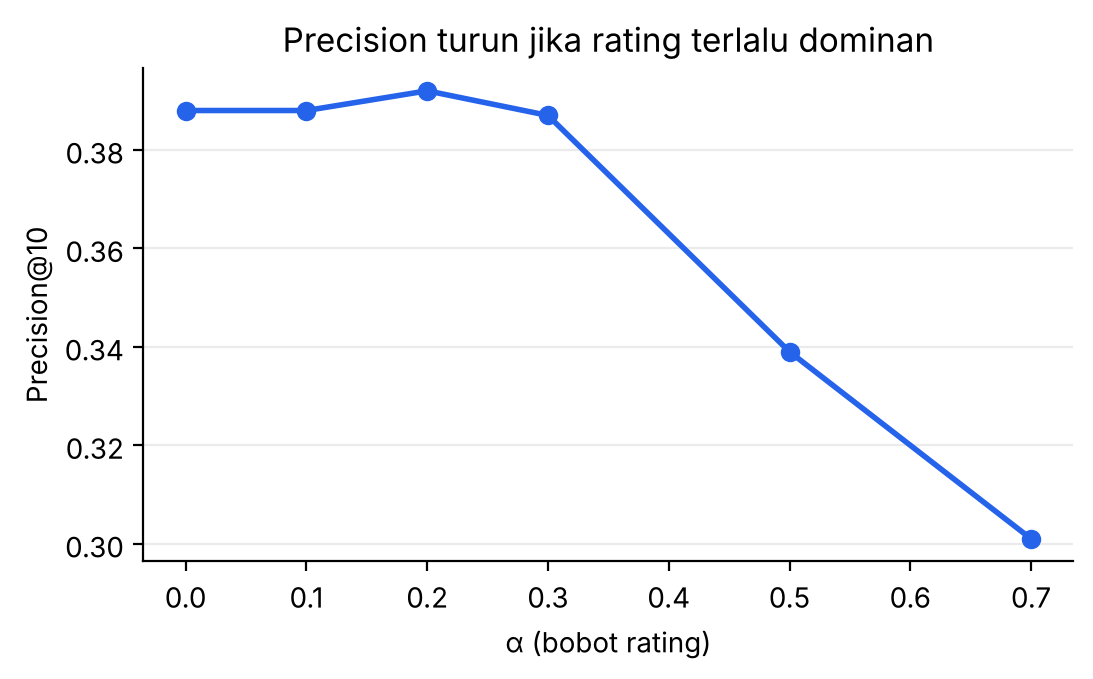

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(sw['alpha'], sw['P@10'], marker='o', color='#2563eb', lw=2)
ax.set_xlabel('α (bobot rating)'); ax.set_ylabel('Precision@10'); ax.set_title('Precision turun jika rating terlalu dominan')
ax.spines[['top','right']].set_visible(False); ax.grid(axis='y', alpha=.25); plt.show()

**Pilihan default α = 0,2** [Usulan]: Precision tidak turun dibanding α = 0, tetapi film berating tinggi naik di urutan. Di atas ≈ 0,3 Precision mulai turun.
Tim boleh mengubahnya lewat `DEFAULT_CONFIG["alpha"]` atau argumen `--alpha` di `build_model`.

### Menggabungkan riwayat: `max` vs `mean`
`max` (default) = kandidat dari tiap film riwayat digabung, nilai terbaik yang dipakai (sesuai PRD, cocok untuk selera beragam).
`mean` = film yang mirip dengan *banyak* film riwayat naik. Pengguna simulasi di bawah punya selera satu genre, jadi mengunggulkan `mean`; hasilnya belum tentu berlaku untuk pengguna asli.

In [8]:
pd.DataFrame({agg: evaluate_personal(model, agg=agg) for agg in ['max','mean']}).T[['P@5','R@5','P@10','R@10']].round(3)

,P@5,R@5,P@10,R@10
max,0.256,0.009,0.230,0.015
mean,0.300,0.011,0.273,0.019


## 6. Evaluasi Precision@K dan Recall@K (K = 5 dan 10)
**Definisi relevan [Usulan, perlu disepakati tim]:** film *j* relevan terhadap acuan *q* jika Jaccard genre(*j*, *q*) ≥ 0,5.
Tiga fungsi diuji sesuai PRD §14: film serupa, rekomendasi personal (pengguna simulasi: 3 film riwayat satu selera, relevan = film berating ≥ 6,5 dengan selera yang sama yang belum ada di riwayat), dan cari film serupa manual (acuan dari 200 film populer, 12 hasil).

Recall@K otomatis kecil karena himpunan relevan berisi ratusan film (kolom `avg_relevant`); bandingkan dengan baseline, bukan dengan 1,0.

In [9]:
final = evaluate_all(model); final.round(4)

,P@5,R@5,P@10,R@10,avg_relevant,n_queries
Film serupa (recommend),0.4093,0.0047,0.392,0.0091,572.4167,300.0
Rekomendasi personal (recommend_for_user),0.2560,0.0088,0.230,0.0153,264.3800,100.0
"Cari film serupa manual (recommend, n=12)",0.5040,0.0076,0.457,0.0128,546.6400,100.0


,P@5,R@5,P@10,R@10
Model (recommend),0.4093,0.0047,0.3920,0.0091
Baseline populer,0.1560,0.0012,0.1247,0.0023
Baseline acak,0.1140,0.0011,0.1127,0.0020


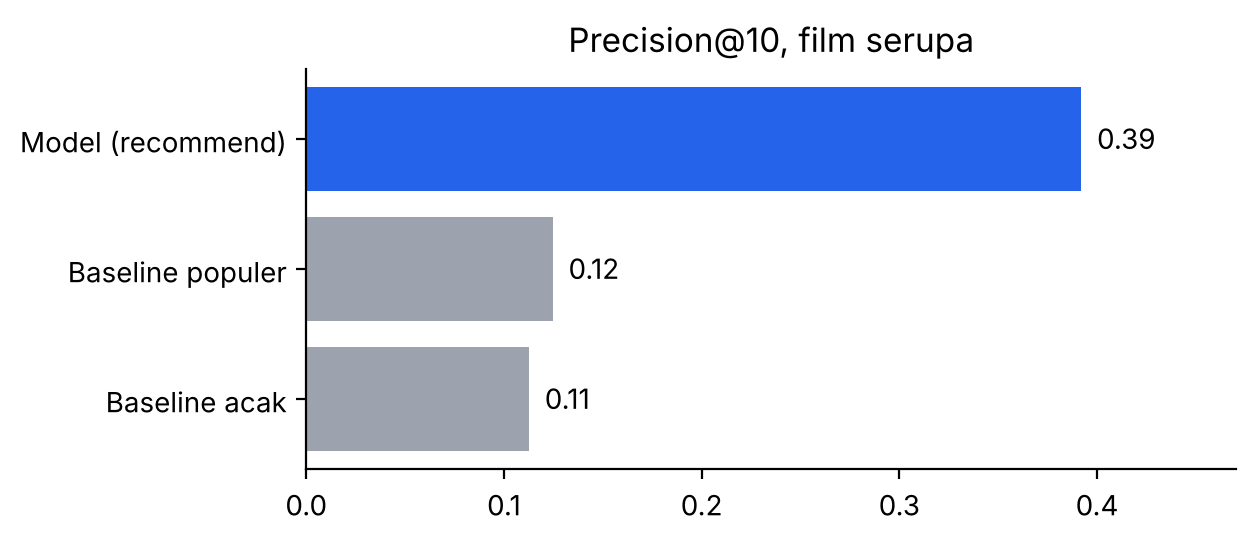

In [10]:
q = sample_queries(model, 300, seed=42)
base = pd.DataFrame({
    'Model (recommend)': evaluate_similar(model, q),
    'Baseline populer':  evaluate_similar(model, q, recommend_fn=popular_baseline(model)),
    'Baseline acak':     evaluate_similar(model, q, recommend_fn=random_baseline(model)),
}).T[['P@5','R@5','P@10','R@10']]
display(base.round(4))
fig, ax = plt.subplots(figsize=(6, 2.6))
vals = base['P@10']; colors = ['#2563eb', '#9ca3af', '#9ca3af']
bars = ax.barh(vals.index[::-1], vals.values[::-1], color=colors[::-1])
for b, v in zip(bars, vals.values[::-1]): ax.text(v + .008, b.get_y()+b.get_height()/2, f'{v:.2f}', va='center')
ax.set_xlim(0, max(vals)*1.2); ax.set_title('Precision@10, film serupa'); ax.spines[['top','right']].set_visible(False); plt.show()

## 7. Distribusi `similarity` (untuk ambang warna badge, isu #14)
Desain memakai ≥ 80 kuning, ≥ 60 hijau, selain itu abu. Cosine TF-IDF asli jauh lebih rendah, jadi ambang perlu disesuaikan dengan sebaran di bawah.

,P10,P25,median,P75,P90,P99
% Mirip (Top-10),9.1,10.5,12.5,15.4,19.3,30.0


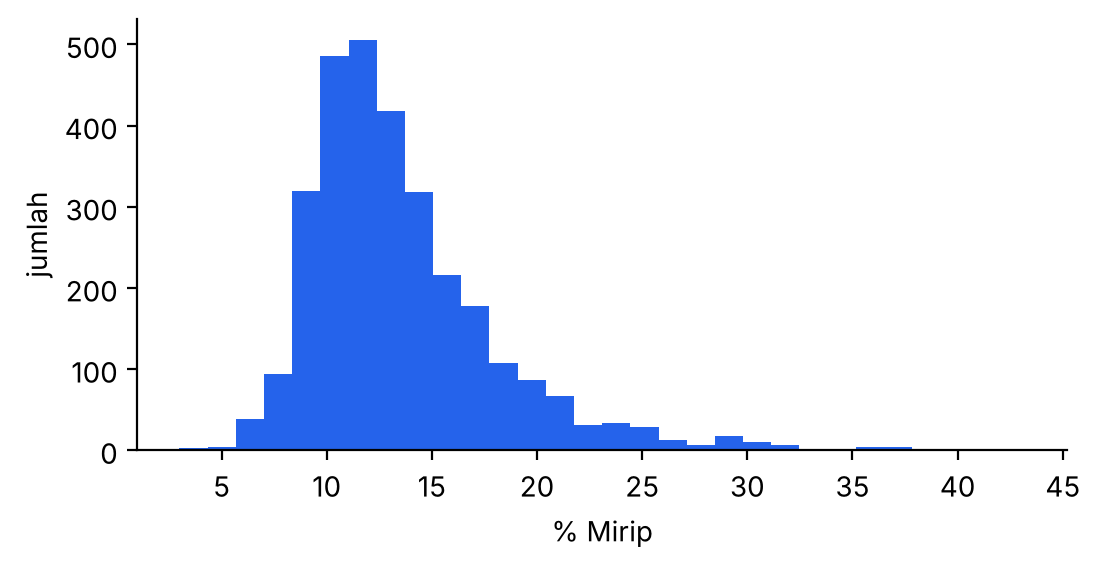

In [11]:
sims = np.array([x['similarity'] for qq in q for x in model.recommend(qq, 10)])
pct = pd.Series(np.percentile(sims*100, [10, 25, 50, 75, 90, 99]).round(1), index=['P10','P25','median','P75','P90','P99'], name='% Mirip (Top-10)')
display(pct.to_frame().T)
fig, ax = plt.subplots(figsize=(6, 2.8)); ax.hist(sims*100, bins=30, color='#2563eb'); ax.set_xlabel('% Mirip'); ax.set_ylabel('jumlah'); ax.spines[['top','right']].set_visible(False); plt.show()

**Usulan ambang** (menyesuaikan sebaran di atas): kuning = di atas P90, hijau = di atas median, sisanya abu. Angkanya harus dihitung ulang pada CSV asli.

## 8. Personalisasi dan cold start

In [12]:
hist = [int(x) for x in model.movies.sort_values('vote_count', ascending=False)['id'].iloc[[0, 5, 10]]]
print('Riwayat (terbaru dulu):', [model.movies.set_index('id').loc[h, 'title'] for h in hist])
pd.DataFrame(model.recommend_for_user(hist, 8))[['title','similarity','score','source_movie_id','reasons']]

Riwayat (terbaru dulu): ['Inception', 'Interstellar', 'Fight Club']


,title,similarity,score,source_movie_id,reasons
0,The Matrix,0.1601,1.0000,157336,"[Genre: Science Fiction, Kata kunci: saving, t..."
1,Starship Troopers,0.1431,0.8245,157336,"[Genre: Science Fiction, Adventure, Kata kunci..."
2,Abduction,0.1449,0.7891,27205,"[Genre: Action, Mystery, Thriller, Kata kunci:..."
3,About Time,0.1218,0.7758,157336,"[Genre: Science Fiction, Drama, Kata kunci: fa..."
4,The Matrix Revolutions,0.1351,0.7736,157336,"[Genre: Science Fiction, Adventure, Kata kunci..."
5,Space Pirate Captain Harlock,0.1310,0.7468,157336,[Genre: Science Fiction]
6,Space Cowboys,0.1313,0.7446,157336,"[Genre: Adventure, Kata kunci: nasa]"
7,Raging Bull,0.1127,0.7040,550,[Genre: Drama]


In [13]:
print('Riwayat kosong -> popular():')
pd.DataFrame(model.recommend_for_user([], 8))[['title','vote_average','vote_count','score']]

Riwayat kosong -> popular():


,title,vote_average,vote_count,score
0,The Shawshank Redemption,8.5,8205,0.8254
1,Fight Club,8.3,9413,0.8101
2,The Godfather,8.4,5893,0.8085
3,Pulp Fiction,8.3,8428,0.8080
4,The Dark Knight,8.2,12002,0.8048
5,Forrest Gump,8.2,7927,0.7979
6,Inception,8.1,13752,0.7973
7,Interstellar,8.1,10867,0.7942


## 9. Menyimpan artefak untuk backend
```
python -m src.build_model --csv data/movies_clean_final.csv --out models/recommender.joblib
```
Backend memakai `from src.recommender import recommend, recommend_for_user, popular` (lihat `docs/model-README.md`).